# Mini-Transformer end-to-end: vom Satz zum trainierten Modell

**Didaktisches Ziel:** *Alle Bausteine aus dem Skript zusammen in einem echten, trainierbaren Modell: Tokenisierung, Embedding, Self-Attention, Feedforward, Residual, LayerNorm, $W_{out}$, Softmax, Cross-Entropy, Training und Inferenz.*

Dieses Notebook gehört zu den Folien **„Was fehlt in dem Rechenbeispiel?“** und **„Training vs. Inferenz“**.
Das Rechenbeispiel im Skript hat Feedforward, Residual und LayerNorm bewusst weggelassen. Hier sind sie dabei.

| Baustein | Rechenbeispiel im Skript | dieses Notebook | GPT-2 (klein) |
| :--- | :---: | :---: | :---: |
| Tokenisierung | ja | ja (Wörter) | ja (BPE) |
| Embedding | ja | 16 Dim. | 768 Dim. |
| Self-Attention | ja, 1 Schicht | ja, 2 Schichten | 12 Schichten |
| Feedforward (MLP mit GELU) | nein | **ja** | ja |
| Residual Connections | nein | **ja** | ja |
| LayerNorm | nein | **ja** | ja |
| Parameter | – | ca. 7 000 | ca. 124 Mio. |

> Wir verwenden PyTorch (in Colab vorinstalliert), schreiben die Attention aber **selbst aus**, damit $W_Q$, $W_K$, $W_V$ und die Maske sichtbar bleiben. Das Training dauert auf einer normalen CPU nur Sekunden.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.set_printoptions(precision=3, suppress=True)

## 1) Trainingsdaten und Tokenisierung

Unser „Internet“ besteht aus 12 Sätzen über Hauptstädte, jeweils in zwei Formulierungen.
Tokenisiert wird ganz einfach an Leerzeichen. Am Anfang jedes Satzes steht ein Start-Token `<BOS>` (*beginning of sequence*).

In [2]:
paare = [("Paris", "Frankreich"), ("Berlin", "Deutschland"), ("Madrid", "Spanien"),
         ("Rom", "Italien"), ("Wien", "Österreich"), ("Bern", "Schweiz")]

saetze = []
for stadt, land in paare:
    saetze.append(f"{stadt} ist die Hauptstadt von {land} .")
    saetze.append(f"die Hauptstadt von {land} ist {stadt} .")

vocab = ["<BOS>"] + sorted({w for s in saetze for w in s.split()})
stoi = {w: i for i, w in enumerate(vocab)}

def encode(text):
    return [stoi["<BOS>"]] + [stoi[w] for w in text.split()]

def decode(ids):
    return " ".join(vocab[i] for i in ids)

daten = torch.tensor([encode(s) for s in saetze])   # alle Sätze sind gleich lang
print("Vokabular:", len(vocab), "Tokens")
print(vocab)
print("\nDaten-Tensor:", tuple(daten.shape), "(Sätze × Tokens)")
print("Satz 0 als IDs:", daten[0].tolist())
print("Satz 0 zurück: ", decode(daten[0].tolist()))

Vokabular: 18 Tokens
['<BOS>', '.', 'Berlin', 'Bern', 'Deutschland', 'Frankreich', 'Hauptstadt', 'Italien', 'Madrid', 'Paris', 'Rom', 'Schweiz', 'Spanien', 'Wien', 'die', 'ist', 'von', 'Österreich']

Daten-Tensor: (12, 8) (Sätze × Tokens)
Satz 0 als IDs: [0, 9, 15, 14, 6, 16, 5, 1]
Satz 0 zurück:  <BOS> Paris ist die Hauptstadt von Frankreich .


**Next-Token-Prediction als Trainingsaufgabe:** Eingabe ist der Satz ohne das letzte Token, Ziel ist der Satz um eins verschoben.
An jeder Position soll das Modell das **nächste** Token vorhersagen.

In [3]:
X = daten[:, :-1]   # Eingabe
Y = daten[:, 1:]    # Ziel: jeweils das nächste Token

for pos in range(X.shape[1]):
    print(f"sieht: {decode(X[0, :pos+1].tolist()):<40} → soll vorhersagen: {vocab[Y[0, pos]]}")

sieht: <BOS>                                    → soll vorhersagen: Paris
sieht: <BOS> Paris                              → soll vorhersagen: ist
sieht: <BOS> Paris ist                          → soll vorhersagen: die
sieht: <BOS> Paris ist die                      → soll vorhersagen: Hauptstadt
sieht: <BOS> Paris ist die Hauptstadt           → soll vorhersagen: von
sieht: <BOS> Paris ist die Hauptstadt von       → soll vorhersagen: Frankreich
sieht: <BOS> Paris ist die Hauptstadt von Frankreich → soll vorhersagen: .


## 2) Das Modell

Ein Transformer-Block (wie in GPT, „Pre-LN“-Variante):

$$
\begin{aligned}
x &\leftarrow x + \text{Attention}(\text{LayerNorm}(x)) \\
x &\leftarrow x + \text{MLP}(\text{LayerNorm}(x))
\end{aligned}
$$

Das „$x +$“ ist jeweils die **Residual-Verbindung**. Die Attention ist dieselbe Rechnung wie im Skript:
$\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}} + \text{Maske}\right) V$ mit $Q = xW_Q$, $K = xW_K$, $V = xW_V$.

Die Schalter `mlp`, `residual` und `layernorm` brauchen wir später, um einzelne Bausteine abzuschalten.

In [4]:
class SelfAttention(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.W_Q = nn.Linear(d, d, bias=False)
        self.W_K = nn.Linear(d, d, bias=False)
        self.W_V = nn.Linear(d, d, bias=False)
        self.W_O = nn.Linear(d, d, bias=False)   # Ausgabeprojektion
        self.A = None                            # letzte Attention-Gewichte (zum Anschauen)

    def forward(self, x):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)
        S = Q @ K.transpose(-2, -1) / math.sqrt(K.shape[-1])
        n = x.shape[-2]
        zukunft = torch.triu(torch.ones(n, n, dtype=torch.bool), diagonal=1)
        S = S.masked_fill(zukunft, float("-inf"))           # Causal Mask
        A = S.softmax(dim=-1)
        self.A = A.detach()
        return self.W_O(A @ V)


class Block(nn.Module):
    def __init__(self, d, mlp=True, residual=True, layernorm=True):
        super().__init__()
        self.attn = SelfAttention(d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d)) if mlp else None
        self.ln1 = nn.LayerNorm(d) if layernorm else nn.Identity()
        self.ln2 = nn.LayerNorm(d) if layernorm else nn.Identity()
        self.residual = residual

    def forward(self, x):
        a = self.attn(self.ln1(x))
        x = x + a if self.residual else a
        if self.mlp is not None:
            m = self.mlp(self.ln2(x))
            x = x + m if self.residual else m
        return x


class MiniTransformer(nn.Module):
    def __init__(self, vocab_size, max_len, d=16, n_layers=2, **schalter):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d)          # Embedding-Matrix
        self.pos_emb = nn.Embedding(max_len, d)             # gelerntes Positional Encoding
        self.blocks = nn.ModuleList([Block(d, **schalter) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d) if schalter.get("layernorm", True) else nn.Identity()
        self.W_out = nn.Linear(d, vocab_size)               # Projektion auf das Vokabular

    def forward(self, ids):
        pos = torch.arange(ids.shape[-1])
        x = self.tok_emb(ids) + self.pos_emb(pos)
        for block in self.blocks:
            x = block(x)
        return self.W_out(self.ln_f(x))                     # Logits


modell = MiniTransformer(len(vocab), max_len=X.shape[1])
print(f"Parameter insgesamt: {sum(p.numel() for p in modell.parameters()):,}".replace(",", "."))
for name, p in modell.named_parameters():
    if "blocks.1" not in name:   # Block 1 ist genauso aufgebaut wie Block 0
        print(f"  {name:<28} {tuple(p.shape)}")

Parameter insgesamt: 7.170
  tok_emb.weight               (18, 16)
  pos_emb.weight               (7, 16)
  blocks.0.attn.W_Q.weight     (16, 16)
  blocks.0.attn.W_K.weight     (16, 16)
  blocks.0.attn.W_V.weight     (16, 16)
  blocks.0.attn.W_O.weight     (16, 16)
  blocks.0.mlp.0.weight        (64, 16)
  blocks.0.mlp.0.bias          (64,)
  blocks.0.mlp.2.weight        (16, 64)
  blocks.0.mlp.2.bias          (16,)
  blocks.0.ln1.weight          (16,)
  blocks.0.ln1.bias            (16,)
  blocks.0.ln2.weight          (16,)
  blocks.0.ln2.bias            (16,)
  ln_f.weight                  (16,)
  ln_f.bias                    (16,)
  W_out.weight                 (18, 16)
  W_out.bias                   (18,)


## 3) Vor dem Training: reines Raten

Die Gewichte sind zufällig. Die Wahrscheinlichkeiten für das nächste Token sind deshalb ungefähr gleich verteilt.
Bei 18 Tokens im Vokabular erwartet man einen Loss von etwa $\ln(18) \approx 2.89$.

In [5]:
def naechstes_token(modell, text, k=3):
    ids = torch.tensor(encode(text))
    with torch.no_grad():
        p = modell(ids)[-1].softmax(-1)
    top = p.topk(k)
    return [(vocab[i], round(v.item(), 3)) for v, i in zip(top.values, top.indices)]

with torch.no_grad():
    loss0 = F.cross_entropy(modell(X).reshape(-1, len(vocab)), Y.reshape(-1)).item()
print(f"Loss vor dem Training: {loss0:.3f}   (ln 18 = {math.log(18):.3f})")
print("'Paris ist die Hauptstadt von' →", naechstes_token(modell, "Paris ist die Hauptstadt von"))

Loss vor dem Training: 3.116   (ln 18 = 2.890)
'Paris ist die Hauptstadt von' → [('Bern', 0.197), ('Italien', 0.089), ('Spanien', 0.084)]


## 4) Training: Loss, Backpropagation, Gewichte anpassen

Genau der Ablauf aus dem Skript, nur automatisch:

1. **Vorwärts:** Logits berechnen
2. **Loss:** Cross-Entropy zwischen Vorhersage und tatsächlichem nächsten Token
3. **Rückwärts:** `loss.backward()` berechnet alle Gradienten (Backpropagation)
4. **Update:** Der Optimierer (Adam, eine verbesserte Variante des Gradientenabstiegs) verschiebt alle Gewichte ein Stück gegen den Gradienten

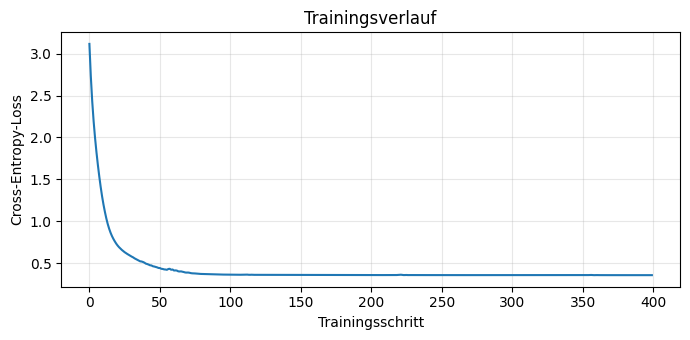

Loss am Anfang: 3.116, am Ende: 0.356


In [6]:
def trainiere(modell, schritte=400, lr=1e-2):
    opt = torch.optim.Adam(modell.parameters(), lr=lr)
    verlauf = []
    for _ in range(schritte):
        logits = modell(X)                                            # 1) vorwärts
        loss = F.cross_entropy(logits.reshape(-1, len(vocab)), Y.reshape(-1))   # 2) Loss
        opt.zero_grad()
        loss.backward()                                               # 3) Backpropagation
        opt.step()                                                    # 4) Gewichte anpassen
        verlauf.append(loss.item())
    return verlauf

verlauf = trainiere(modell)

plt.figure(figsize=(7, 3.5))
plt.plot(verlauf)
plt.xlabel("Trainingsschritt")
plt.ylabel("Cross-Entropy-Loss")
plt.title("Trainingsverlauf")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Loss am Anfang: {verlauf[0]:.3f}, am Ende: {verlauf[-1]:.3f}")

**Warum geht der Loss nicht auf 0?** Manche Tokens sind grundsätzlich nicht vorhersagbar, egal wie gut das Modell ist:

- Nach `<BOS>` kann jeder der 6 Städtenamen oder „die“ kommen.
- Nach „die Hauptstadt von“ kann jedes der 6 Länder kommen.

Alles andere ist eindeutig. Der beste erreichbare Loss lässt sich ausrechnen:

In [7]:
# Position 1: nach <BOS> -> "die" (6 von 12 Sätzen) oder eine bestimmte Stadt (je 1 von 12)
h_start = -(0.5 * math.log(0.5) + 6 * (1/12) * math.log(1/12))
# Bei Formulierung 2 an Position 4: nach "die Hauptstadt von" ist jedes Land gleich wahrscheinlich
h_land = math.log(6) / 2         # tritt nur in der Hälfte der Sätze auf
n_pos = X.shape[1]
minimum = (h_start + h_land) / n_pos
print(f"theoretisches Minimum des Loss: {minimum:.3f}")
print(f"erreicht:                       {verlauf[-1]:.3f}")

theoretisches Minimum des Loss: 0.355
erreicht:                       0.356


Das Modell erreicht praktisch das Minimum: Es hat alles gelernt, was sich aus diesen Daten lernen **lässt**.

## 5) Was hat das Modell gelernt?

In [8]:
for text in ["Paris ist die Hauptstadt von", "Rom ist die Hauptstadt von",
             "die Hauptstadt von Spanien ist", "die Hauptstadt von"]:
    print(f"{text:<32} → {naechstes_token(modell, text)}")

Paris ist die Hauptstadt von     → [('Frankreich', 0.998), ('Österreich', 0.0), ('Italien', 0.0)]
Rom ist die Hauptstadt von       → [('Italien', 0.998), ('Spanien', 0.001), ('Frankreich', 0.0)]
die Hauptstadt von Spanien ist   → [('Madrid', 0.999), ('Paris', 0.0), ('Berlin', 0.0)]
die Hauptstadt von               → [('Italien', 0.168), ('Spanien', 0.167), ('Schweiz', 0.167)]


Beim letzten Beispiel verteilt das Modell die Wahrscheinlichkeit auf die sechs Länder. Ohne weiteren Kontext ist das genau richtig.

### Worauf achtet „von“?

Wie im Rechenbeispiel des Skripts schauen wir auf die Attention-Gewichte des Tokens „von“, jetzt aber **gelernt** statt von Hand gesetzt:

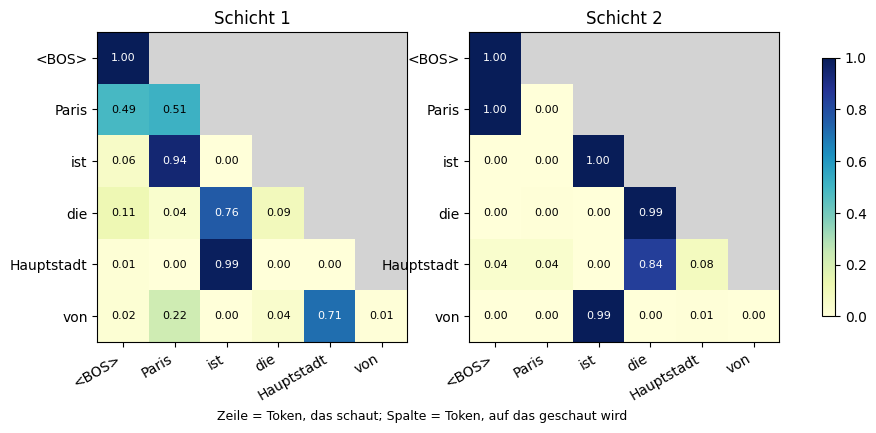

Schicht 1, Zeile 'von': {'<BOS>': 0.02, 'Paris': 0.22, 'ist': 0.0, 'die': 0.04, 'Hauptstadt': 0.71, 'von': 0.01}
Schicht 2, Zeile 'von': {'<BOS>': 0.0, 'Paris': 0.0, 'ist': 0.99, 'die': 0.0, 'Hauptstadt': 0.01, 'von': 0.0}


In [9]:
text = "Paris ist die Hauptstadt von"
ids = torch.tensor(encode(text))
with torch.no_grad():
    modell(ids)
tokens = ["<BOS>"] + text.split()

fig, axes = plt.subplots(1, len(modell.blocks), figsize=(11, 4.2))
for l, (ax, block) in enumerate(zip(axes, modell.blocks)):
    A = block.attn.A.numpy()
    cmap = plt.get_cmap("YlGnBu").copy()
    cmap.set_bad("lightgray")
    im = ax.imshow(np.ma.masked_where(np.triu(np.ones_like(A, dtype=bool), k=1), A), cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(len(tokens)), tokens, rotation=30, ha="right")
    ax.set_yticks(range(len(tokens)), tokens)
    for i in range(len(tokens)):
        for j in range(i + 1):
            ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if A[i, j] > 0.6 else "black")
    ax.set_title(f"Schicht {l + 1}")
fig.colorbar(im, ax=axes, shrink=0.8)
fig.text(0.42, -0.06, "Zeile = Token, das schaut; Spalte = Token, auf das geschaut wird", ha="center", fontsize=9)
plt.show()

for l, block in enumerate(modell.blocks):
    print(f"Schicht {l + 1}, Zeile 'von':", dict(zip(tokens, block.attn.A[-1].numpy().round(2))))

Die genauen Werte hängen vom Zufallsstart ab. In unserem Lauf sieht man ein typisches Muster:

- **Schicht 1:** „von“ achtet vor allem auf **„Hauptstadt“**, wie im Rechenbeispiel des Skripts.
- **Schicht 1:** „ist“ achtet fast nur auf **„Paris“**. Damit trägt der Vektor von „ist“ ab jetzt die Information, um welche Stadt es geht.
- **Schicht 2:** „von“ holt sich diese Information bei **„ist“** ab.

Die Stadt wird also über **zwei Schichten weitergereicht**: Paris → ist → von. Danach kann $W_{out}$ aus dem Vektor von „von“ das Land „Frankreich“ ablesen.
Deshalb haben echte Modelle viele Schichten: Jede Schicht kann Information einen Schritt weitertragen und neu kombinieren.

Niemand hat dem Modell diese Regeln vorgegeben. Die Attention-Muster sind allein durch das Minimieren des Loss entstanden.

### Gelernte Embeddings

Die Zeilen der Embedding-Matrix wurden mittrainiert. Bilden Städte und Länder eigene Gruppen, wie im Notebook `embeddings_aehnlichkeit_pca_analogie.ipynb`?

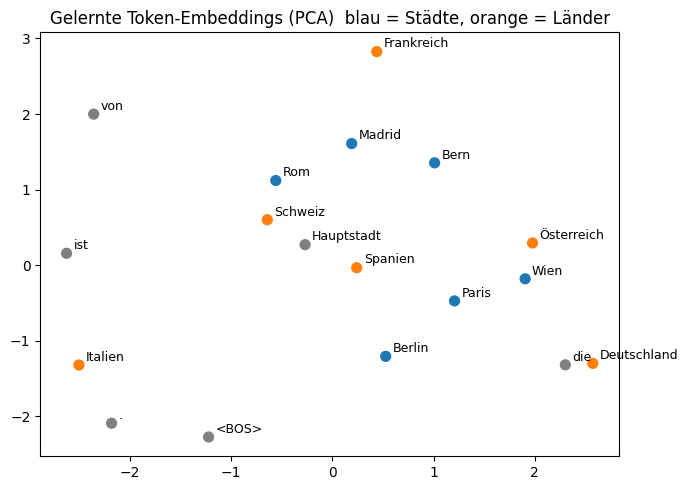

In [10]:
E = modell.tok_emb.weight.detach().numpy()
Ec = E - E.mean(axis=0)
_, _, Vt = np.linalg.svd(Ec, full_matrices=False)
P = Ec @ Vt[:2].T

staedte = {s for s, _ in paare}
laender = {l for _, l in paare}
farbe = ["tab:blue" if w in staedte else "tab:orange" if w in laender else "gray" for w in vocab]

plt.figure(figsize=(7, 5))
plt.scatter(P[:, 0], P[:, 1], c=farbe, s=50)
for w, (x, y) in zip(vocab, P):
    plt.annotate(w, (x, y), textcoords="offset points", xytext=(5, 3), fontsize=9)
plt.title("Gelernte Token-Embeddings (PCA)  blau = Städte, orange = Länder")
plt.tight_layout()
plt.show()

**Eher nicht.** Städte und Länder liegen durcheinander. Für unsere Aufgabe muss das Modell jede Stadt nur ihrem Land zuordnen, und dafür reicht es, dass alle Vektoren **unterscheidbar** sind.
Ähnliche Embeddings für ähnliche Wörter entstehen erst, wenn sich daraus ein Vorteil ergibt: bei vielen Texten, in denen Städte immer wieder in ähnlichen Zusammenhängen auftauchen. Mit 12 Sätzen gibt es diesen Druck nicht.

## 6) Inferenz: Text erzeugen, ohne zu lernen

Bei der Inferenz rechnet das Modell nur vorwärts. Das erzeugte Token wird angehängt, und die Vorhersage beginnt von vorn.
Mit einer Prüfsumme über alle Gewichte zeigen wir: **Beim Antworten ändert sich kein einziges Gewicht.**

In [11]:
def pruefsumme(modell):
    return sum(p.detach().double().sum().item() for p in modell.parameters())

@torch.no_grad()
def generiere(modell, start, max_neu=8, T=1.0, greedy=True):
    ids = encode(start)
    for _ in range(max_neu):
        logits = modell(torch.tensor(ids))[-1] / T
        p = logits.softmax(-1)
        nxt = int(p.argmax()) if greedy else int(torch.multinomial(p, 1))
        ids.append(nxt)
        if vocab[nxt] == ".":
            break
    return decode(ids[1:])

vorher = pruefsumme(modell)
for start in ["Berlin", "Wien ist", "die Hauptstadt von Italien"]:
    print(f"{start:<28} → {generiere(modell, start)}")
nachher = pruefsumme(modell)
print(f"\nPrüfsumme der Gewichte vorher {vorher:.6f}, nachher {nachher:.6f}, gleich: {vorher == nachher}")

Berlin                       → Berlin ist die Hauptstadt von Deutschland .
Wien ist                     → Wien ist die Hauptstadt von Österreich .
die Hauptstadt von Italien   → die Hauptstadt von Italien ist Rom .

Prüfsumme der Gewichte vorher 120.997983, nachher 120.997983, gleich: True


### Was das Modell nicht weiß

Fragen wir nach einem Land, das nie in den Trainingsdaten vorkam:

In [12]:
try:
    print(generiere(modell, "die Hauptstadt von Portugal ist"))
except KeyError as fehler:
    print(f"Fehler: {fehler} ist nicht im Vokabular. Das Modell hat dieses Wort nie gesehen.")

Fehler: 'Portugal' ist nicht im Vokabular. Das Modell hat dieses Wort nie gesehen.


Ein großes LLM hätte „Portugal“ zwar im Vokabular, aber das Prinzip ist dasselbe: **Wissen, das nicht in den Trainingsdaten war, steckt nicht in den Gewichten**, und beim Antworten wird nichts nachgelernt.
Genau hier setzt **RAG** an (nächster Abschnitt im Skript): Das fehlende Wissen wird zur Laufzeit als Kontext mitgegeben.

## 7) Was bringen Feedforward, Residual und LayerNorm?

Wir trainieren dasselbe Modell mehrmals und schalten jeweils einen Baustein ab.
Damit der Unterschied sichtbar wird, nehmen wir **4 Schichten**: Je tiefer ein Netz ist, desto wichtiger werden Residual-Verbindungen und LayerNorm.

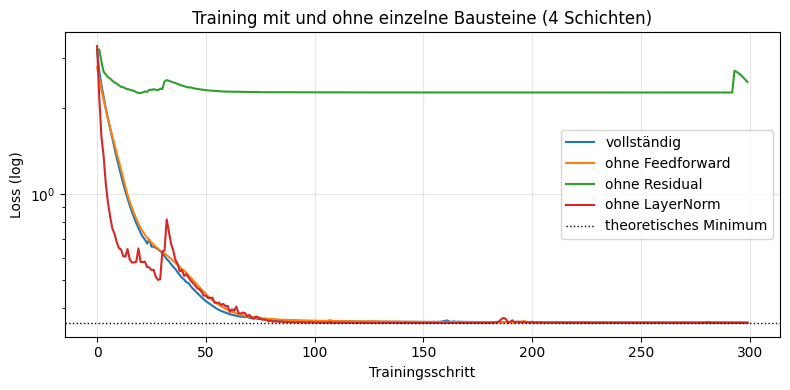

vollständig        Loss nach 50 Schritten 0.430, nach 300 Schritten 0.356
ohne Feedforward   Loss nach 50 Schritten 0.456, nach 300 Schritten 0.356
ohne Residual      Loss nach 50 Schritten 2.321, nach 300 Schritten 2.471
ohne LayerNorm     Loss nach 50 Schritten 0.442, nach 300 Schritten 0.355


In [13]:
varianten = {
    "vollständig":       dict(),
    "ohne Feedforward":  dict(mlp=False),
    "ohne Residual":     dict(residual=False),
    "ohne LayerNorm":    dict(layernorm=False),
}
verlaeufe = {}
for name, schalter in varianten.items():
    torch.manual_seed(0)
    m = MiniTransformer(len(vocab), max_len=X.shape[1], n_layers=4, **schalter)
    verlaeufe[name] = trainiere(m, schritte=300)

plt.figure(figsize=(8, 4))
for name, v in verlaeufe.items():
    plt.plot(v, label=name)
plt.axhline(minimum, color="black", ls=":", lw=1, label="theoretisches Minimum")
plt.yscale("log")
plt.xlabel("Trainingsschritt")
plt.ylabel("Loss (log)")
plt.title("Training mit und ohne einzelne Bausteine (4 Schichten)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for name, v in verlaeufe.items():
    print(f"{name:<18} Loss nach 50 Schritten {v[49]:.3f}, nach 300 Schritten {v[-1]:.3f}")

**Einordnung:**

- **Ohne Feedforward** verläuft das Training fast genauso. Unser Datensatz ist so klein, dass die Attention allein ausreicht.
- **Ohne LayerNorm** sinkt der Loss anfangs sogar schneller, springt aber immer wieder nach oben: Das Training wird **instabil**.
- **Ohne Residual-Verbindungen** bleibt das Training dagegen bei 4 Schichten weit über dem Minimum hängen: Das Signal (und der Gradient) muss durch jede Schicht hindurch, statt über die Abkürzung „$x +$“ weitergereicht zu werden.

Bei echten Modellen mit 12 bis 96 Schichten werden alle drei Bausteine wichtig: Ohne Residual-Verbindungen und Normierung lassen sich so tiefe Netze praktisch nicht trainieren, und ohne Feedforward fehlt ein Großteil der Parameter, in denen Wissen gespeichert wird.

> Unser Modell hat die 12 Sätze im Grunde **auswendig gelernt**. Ein echtes LLM sieht so viele Texte, dass Auswendiglernen nicht mehr reicht. Es muss allgemeine Muster finden.

## 8) Aufgaben

1. **Neues Wissen:** Füge `("Lissabon", "Portugal")` zu `paare` hinzu und trainiere neu. Funktioniert jetzt die Frage aus Abschnitt 6?
2. **Größe:** Setze `d=4` (wie im Rechenbeispiel des Skripts). Wird das Minimum noch erreicht?
3. **Eine Schicht:** Trainiere mit `n_layers=1`. Worauf achtet „von“ jetzt, wenn kein Weiterreichen über „ist“ mehr möglich ist?
4. **Decoding:** Erzeuge mit `generiere(modell, "die Hauptstadt von", greedy=False)` mehrere Sätze. Warum kommen verschiedene Länder heraus? (Siehe `decoding_temperatur_topk_topp.ipynb`.)

---

### Take-away
**Ein LLM ist im Kern genau dieses Modell, nur viel größer.** Embedding, Attention, Feedforward, Residual und LayerNorm werden in vielen Schichten wiederholt. Training passt die Gewichte an, Inferenz rechnet nur vorwärts.